# Session 14: train a dense model, convert it into a mixture of experts, keep training

**Assignment:** *Train a Linear model and convert that into an MoE! Your call on model size and data, but must show
they continue to train and reduce loss!*

"Linear model" in class means the ordinary dense feed-forward block that every token passes through in full.
The plan:

1. Train a ~21M-parameter dense GPT on TinyStories.
2. At 15M tokens, convert its feed-forward blocks into mixtures of experts, three different ways.
3. Keep training every converted model to 30M tokens.
4. Compare against the dense model trained on the same tokens, and against the same MoE trained from scratch.

On top of the assignment:
- a second growth step, 8 → 32 experts by cloning, which reproduces the "collapse along clone families" failure
  the course describes, and tests its fix;
- a look at what the experts specialise in.

Everything ran on one Apple M1 Pro (MPS, fp32). The training runs are made by `python -m moe.experiments`, which
saves every run to `results/`. This notebook reads those runs and makes every other measurement live.

| piece | where |
|---|---|
| data (TinyStories, 8,192-token BPE, same as Session 13) | `moe/data.py` |
| model: dense FFN or MoE (fp32 router, bias balancing, dropless, hard or sampled top-k) | `moe/model.py` |
| dense → MoE (copy, drop, partition) and MoE → bigger MoE (grow) | `moe/convert.py` |
| training on a shared token axis, routing statistics | `moe/train.py` |
| run order | `moe/experiments.py` |
| specialisation measurements | `moe/analysis.py` |
| tests | `tests/test_moe.py` |

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from moe.model import GPT, GPTConfig
from moe.convert import dense_to_moe, grow
from moe.data import Stream
from moe import analysis as A
from moe.experiments import CONVERT_AT, GROW_AT, METHODS, GROW_RUNS, moe_config, best_at_grow, load as R

GiB = 2 ** 30
RES = ROOT / "results"
ART = ROOT / "submission_artifacts"; ART.mkdir(exist_ok=True)
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
NUM = {}
print("torch", torch.__version__, "| device", DEV, "| conversion at", f"{CONVERT_AT:,}", "| growth at", f"{GROW_AT:,}")

torch 2.14.1 | device mps | conversion at 14,991,360 | growth at 23,986,176


## 1. The models

**The dense model.**
- d = 384, 10 layers, 6 heads, sequence 256.
- An 8,192-token vocabulary with a tied head.
- A GELU feed-forward block of inner width 1,536 (4 × d).

**The mixture of experts** replaces that block in **every** layer and keeps everything else. All three conversions
give each token the same work, about twice the dense FFN:

| method | routed experts | each expert's width | shared expert | top-k | width each token uses |
|---|---|---|---|---|---|
| copy | 8 | 1,536 (a full copy) | – | 2 | 2 × 1,536 = 3,072 |
| drop (r = 0.5) | 8 | 1,536 (copy, half the neurons re-initialised) | – | 2 | 3,072 |
| partition | 8 | 768 (a random half of the neurons) | the dense FFN, 1,536 | 2 | 1,536 + 2 × 768 = 3,072 |

Top-1 with full copies would use the same width as dense, but it has a problem: the single chosen weight is
renormalised to exactly 1, so the router gets no gradient. Top-2 is the smallest choice for which routing is learned.

In [2]:
rows = {}
for name, model in [("dense", GPT(GPTConfig())), ("copy / drop", GPT(moe_config("copy"))),
                    ("partition", GPT(moe_config("partition"))), (f"grown 32 experts (from {best_at_grow()})", grow(GPT(moe_config(best_at_grow())), 4))]:
    rows[name] = dict(total=model.n_params(), active=model.n_active())
    print(f"{name:18s} total {model.n_params()/1e6:7.1f}M   active per token {model.n_active()/1e6:5.1f}M   "
          f"training FLOPs per token ~ 6 x active = {6*model.n_active()/1e6:5.0f} MFLOP")
    del model
NUM["params"] = rows

dense              total    21.0M   active per token  21.0M   training FLOPs per token ~ 6 x active =   126 MFLOP
copy / drop        total   103.6M   active per token  32.8M   training FLOPs per token ~ 6 x active =   197 MFLOP
partition          total    68.2M   active per token  32.8M   training FLOPs per token ~ 6 x active =   197 MFLOP
grown 32 experts (from partition) total   209.8M   active per token  32.9M   training FLOPs per token ~ 6 x active =   197 MFLOP


## 2. What each conversion does to the model at the moment of conversion

The same trained dense checkpoint (at 15M tokens) is converted each way, and every result is scored on the same
validation batches:

- **Copy** should give exactly the dense model's loss. Every expert is identical, and the two chosen weights are
  renormalised to sum to 1, so whatever the new router picks, the output is the dense FFN's output.
- **Drop** and **partition** change the function, so they start from a worse loss and have to recover it.

In [3]:
dense15 = GPT(GPTConfig()); dense15.load_state_dict(torch.load(RES / f"dense_at{CONVERT_AT}.pt", map_location="cpu"))
s = Stream(16, 256, "valid"); batches = [s.next() for _ in range(20)]
def val(model):
    model = model.to(DEV).eval()
    with torch.no_grad():
        return float(np.mean([model(x.to(DEV), y.to(DEV)).item() for x, y in batches]))
at_conv = {"dense": val(dense15)}
for m in METHODS:
    at_conv[m] = val(dense_to_moe(dense15.cpu(), m))
for k, v in at_conv.items():
    print(f"{k:10s} val loss at conversion {v:.4f}   ({v - at_conv['dense']:+.4f} vs dense)")
NUM["val_at_conversion"] = at_conv

dense      val loss at conversion 2.1100   (+0.0000 vs dense)
copy       val loss at conversion 2.1100   (+0.0000 vs dense)
drop       val loss at conversion 2.5789   (+0.4689 vs dense)
partition  val loss at conversion 2.1719   (+0.0619 vs dense)


## 3. Do they continue to train and reduce loss?

The three converted models train from 15M to 30M tokens. The dense run carries on over the same tokens, on the same
schedule: warmup, constant, then decay to 10% over the last 6M. That is the fair comparison: same data, same
learning rate.

Each converted model gets a fresh AdamW and a 0.5M-token re-warmup, because its experts and router are new tensors.

In [4]:
D = R("dense"); RUNS = {m: R(f"moe_{m}") for m in METHODS}
def ev_at(log, t):
    return min(log["evals"], key=lambda e: abs(e["tokens"] - t))
print(f"{'model':10s} {'val @ conv':>10s} {'val @ +1.5M':>11s} {'val @ 24M':>10s} {'final val':>10s} {'vs dense':>9s} "
      f"{'tok/s':>7s} {'peak GiB':>9s}")
NUM["main"] = {}
dfinal = D["final_val_loss"]
for name, log in [("dense", D)] + list(RUNS.items()):
    first = log["evals"][0] if name != "dense" else ev_at(D, CONVERT_AT)
    r = dict(val_at_conv=first["val_loss"], val_after_1_5M=ev_at(log, CONVERT_AT + 1_500_000)["val_loss"],
             val_24M=ev_at(log, GROW_AT)["val_loss"], final_val=log["final_val_loss"], final_train=log["final_train_loss"],
             tok_s=log["tok_per_s"], peak_gib=log["peak_bytes"] / GiB, total=log["n_params"], active=log["n_active"],
             minutes=log["train_seconds"] / 60)
    NUM["main"][name] = r
    print(f"{name:10s} {r['val_at_conv']:10.4f} {r['val_after_1_5M']:11.4f} {r['val_24M']:10.4f} {r['final_val']:10.4f} "
          f"{r['final_val']-dfinal:+9.4f} {r['tok_s']:7.0f} {r['peak_gib']:9.2f}")
print()
for name, log in RUNS.items():
    vals = [e["val_loss"] for e in log["evals"]]
    drops = sum(b < a for a, b in zip(vals, vals[1:]))
    print(f"{name}: validation loss fell at {drops} of {len(vals)-1} evaluations after conversion; "
          f"{vals[0]:.3f} -> {vals[-1]:.3f}")

model      val @ conv val @ +1.5M  val @ 24M  final val  vs dense   tok/s  peak GiB
dense          2.1132      2.0699     1.9375     1.7045   +0.0000   16021      6.47
copy           2.1100      2.1045     1.9836     1.7178   +0.0133    6697     11.03
drop           2.5722      2.1529     1.9795     1.7105   +0.0059    6867     11.07
partition      2.1710      2.0915     1.9349     1.6973   -0.0072    7211     10.57

copy: validation loss fell at 10 of 10 evaluations after conversion; 2.110 -> 1.744
drop: validation loss fell at 10 of 10 evaluations after conversion; 2.572 -> 1.737
partition: validation loss fell at 10 of 10 evaluations after conversion; 2.171 -> 1.724


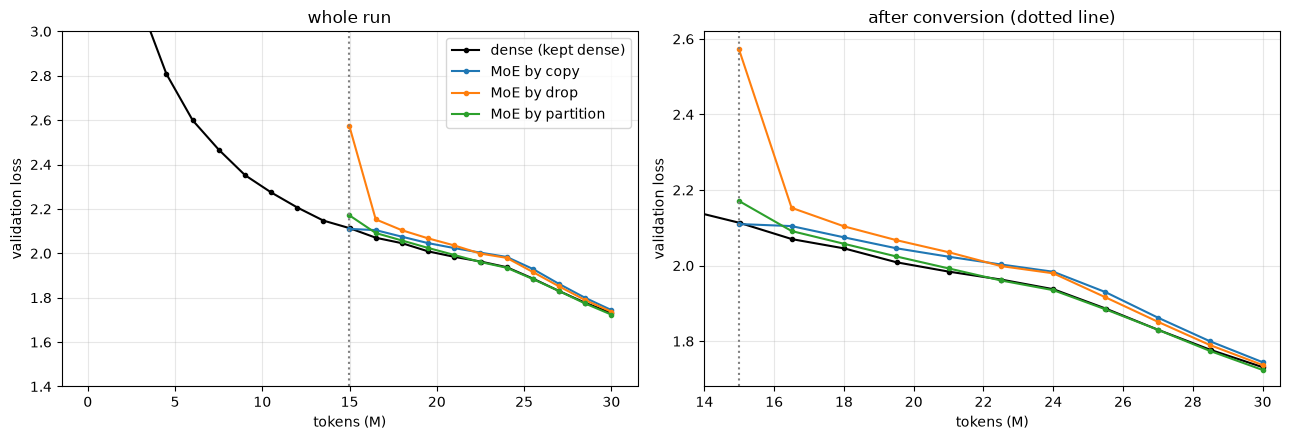

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ev = D["evals"]
for a in ax:
    a.plot([e["tokens"]/1e6 for e in ev], [e["val_loss"] for e in ev], "k-o", ms=3, label="dense (kept dense)")
    for name, log in RUNS.items():
        e2 = log["evals"]
        a.plot([e["tokens"]/1e6 for e in e2], [e["val_loss"] for e in e2], "-o", ms=3, label=f"MoE by {name}")
    a.axvline(CONVERT_AT/1e6, color="grey", ls=":"); a.grid(alpha=.3); a.set_xlabel("tokens (M)"); a.set_ylabel("validation loss")
ax[0].set(ylim=(1.4, 3.0), title="whole run"); ax[0].legend()
ax[1].set(xlim=(CONVERT_AT/1e6 - 1, 30.5), ylim=(1.68, 2.62), title="after conversion (dotted line)")
fig.tight_layout(); fig.savefig(ART / "loss_after_conversion.png", dpi=130); plt.show()

## 4. Routing health after conversion

Every converted model uses the auxiliary-loss-free bias method: after each step, each expert's selection bias
moves ±0.001 towards an even load. Over each 50-step window the log records two things:
- **MaxVio**: (busiest expert's load − mean) / mean. 0 means a perfectly even load, 1 means twice the average.
- **Dead experts**: experts that got no tokens at all in the window.

copy       mean MaxVio first window 0.87, last 0.18, worst 2.53;  dead experts (of 80) worst 1, last 0
drop       mean MaxVio first window 0.95, last 0.14, worst 1.56;  dead experts (of 80) worst 1, last 0
partition  mean MaxVio first window 0.72, last 0.13, worst 1.92;  dead experts (of 80) worst 1, last 0
scratch    mean MaxVio first window 1.37, last 0.02, worst 1.37;  dead experts (of 80) worst 0, last 0


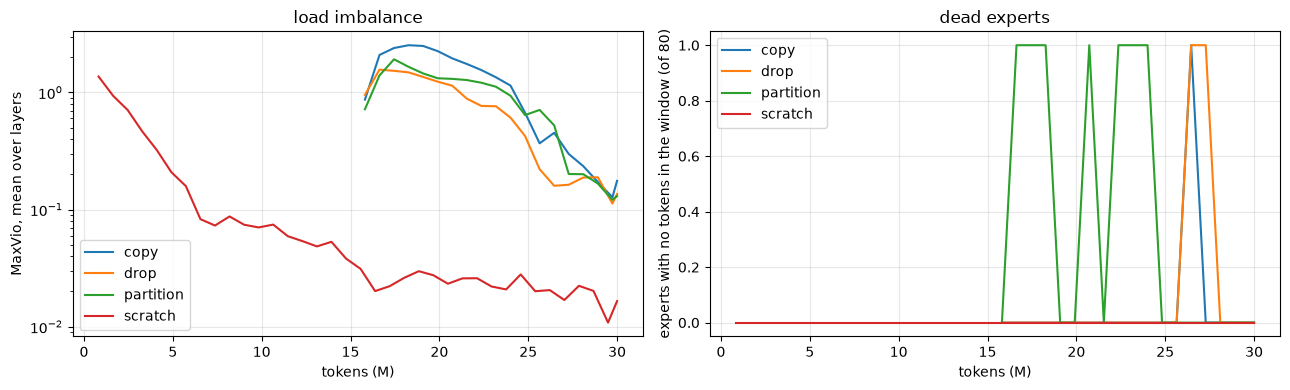

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
NUM["routing"] = {}
for name, log in list(RUNS.items()) + [("scratch", R("moe_scratch"))]:
    tr = log["train"]
    t = [r["tokens"]/1e6 for r in tr]
    mv = [np.mean(r["routing"]["maxvio"]) for r in tr]
    dead = [sum(r["routing"]["dead"]) for r in tr]
    ax[0].plot(t, mv, label=name); ax[1].plot(t, dead, label=name)
    NUM["routing"][name] = dict(maxvio_first=mv[0], maxvio_last=mv[-1], maxvio_max=max(mv), dead_max=max(dead), dead_last=dead[-1])
    print(f"{name:10s} mean MaxVio first window {mv[0]:.2f}, last {mv[-1]:.2f}, worst {max(mv):.2f};  "
          f"dead experts (of 80) worst {max(dead)}, last {dead[-1]}")
ax[0].set(xlabel="tokens (M)", ylabel="MaxVio, mean over layers", title="load imbalance"); ax[0].set_yscale("log")
ax[1].set(xlabel="tokens (M)", ylabel="experts with no tokens in the window (of 80)", title="dead experts")
for a in ax: a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "routing_health.png", dpi=130); plt.show()

## 5. Upcycled against trained from scratch

The same MoE shape (8 experts × 1,536, top-2) also trained from random weights for the full 30M tokens. There are
two fair ways to compare:
- **Same tokens:** every model sees 30M tokens.
- **Same compute:** training FLOPs ≈ 6 × active parameters × tokens. The upcycled models spent the first 15M tokens
  as the cheaper dense model.

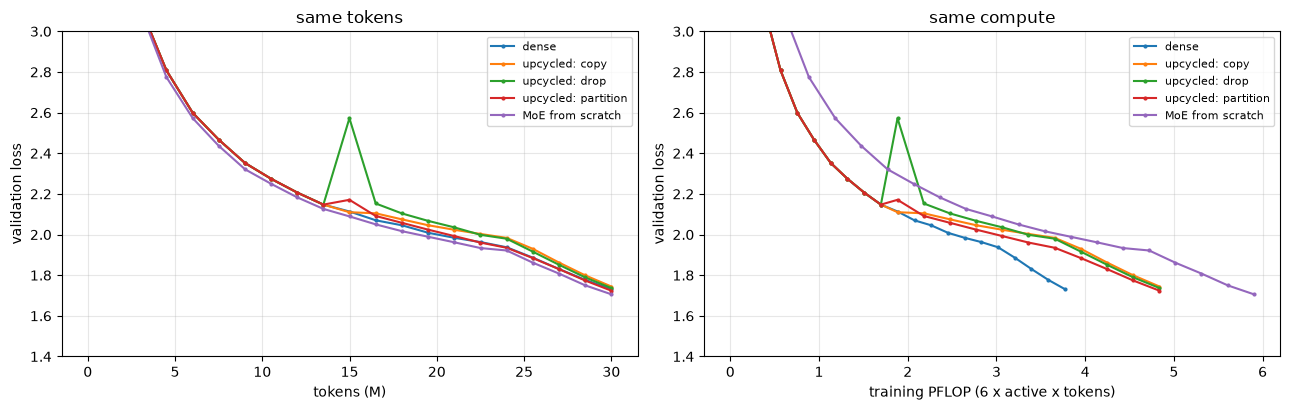

MoE from scratch: final val 1.6779 for 5.90 PFLOP
best upcycled (partition): final val 1.6973 for 4.84 PFLOP
dense: final val 1.7045 for 3.77 PFLOP


In [7]:
SC = R("moe_scratch")
dense_act, moe_act = NUM["params"]["dense"]["active"], NUM["params"]["copy / drop"]["active"]
def flops(log, dense_until=0):
    out = []
    for e in log["evals"]:
        t = e["tokens"]
        f = 6 * dense_act * min(t, dense_until) + 6 * moe_act * max(0, t - dense_until) if dense_until else 6 * (dense_act if log["moe"] is None else moe_act) * t
        out.append(f / 1e15)
    return out
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
curves = [("dense", D, 0)] + [(f"upcycled: {m}", RUNS[m], CONVERT_AT) for m in METHODS] + [("MoE from scratch", SC, 0)]
for name, log, du in curves:
    e = log["evals"]
    if du:
        e = [x for x in D["evals"] if x["tokens"] <= CONVERT_AT] + e
        f = [6 * dense_act * x["tokens"] / 1e15 for x in D["evals"] if x["tokens"] <= CONVERT_AT] + flops(log, du)
    else:
        f = flops(log)
    ax[0].plot([x["tokens"]/1e6 for x in e], [x["val_loss"] for x in e], "-o", ms=2, label=name)
    ax[1].plot(f, [x["val_loss"] for x in e], "-o", ms=2, label=name)
ax[0].set(xlabel="tokens (M)", ylabel="validation loss", ylim=(1.4, 3.0), title="same tokens")
ax[1].set(xlabel="training PFLOP (6 x active x tokens)", ylabel="validation loss", ylim=(1.4, 3.0), title="same compute")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "upcycled_vs_scratch.png", dpi=130); plt.show()
tot_up = (6 * dense_act * CONVERT_AT + 6 * moe_act * (30_000_000 - CONVERT_AT)) / 1e15
tot_sc = 6 * moe_act * SC["tokens_end"] / 1e15
NUM["scratch"] = dict(final_val=SC["final_val_loss"], pflop=tot_sc, upcycled_pflop=tot_up, tok_s=SC["tok_per_s"], minutes=SC["train_seconds"]/60)
best = min(METHODS, key=lambda m: RUNS[m]["final_val_loss"])
print(f"MoE from scratch: final val {SC['final_val_loss']:.4f} for {tot_sc:.2f} PFLOP")
print(f"best upcycled ({best}): final val {RUNS[best]['final_val_loss']:.4f} for {tot_up:.2f} PFLOP")
print(f"dense: final val {D['final_val_loss']:.4f} for {6*dense_act*D['tokens_end']/1e15:.2f} PFLOP")

## 6. Growing again: 8 → 32 experts by cloning, and the clone-family collapse

The course describes a failure from Lightning LM's 20 → 460 expert growth. Each expert was cloned 23 times, the
router rows were tiled with small noise, and hard top-k was used. The dead experts went 27 → 38 → 122 → 154 → 168
of 460 within a few hundred steps. The router can't tell near-identical clones apart, so each clone family settles on
a few members and the rest never receive a token. The fix was sampled ("probabilistic") selection for an early
window, so every clone gets some gradient before the router settles.

Here the best converted MoE at 24M tokens is grown 8 → 32 experts:
- each expert is cloned 4 times, giving 8 families of 4;
- the router rows are tiled, with noise of std 1e-3;
- top-k stays 2, so the compute per token doesn't change.

It then trains 24M → 30M three ways. The ungrown MoE's own 24M → 30M is the baseline.

| run | selection | clones |
|---|---|---|
| grow_hard | hard top-2 throughout | exact copies |
| grow_sample | sampled top-2 for the first 1.5M tokens, then hard | exact copies |
| grow_redraw | hard top-2 throughout | 3 of each family's 4 have half their neurons re-initialised |

grow_hard    dead experts (of 320): worst 24, last window 8;  families (of 80) with all 4 clones alive 78, with only 1 alive 0;  final val 1.7080
grow_sample  dead experts (of 320): worst 25, last window 6;  families (of 80) with all 4 clones alive 78, with only 1 alive 0;  final val 1.7133
grow_redraw  dead experts (of 320): worst 26, last window 8;  families (of 80) with all 4 clones alive 78, with only 1 alive 0;  final val 1.7141
not grown    final val 1.6973


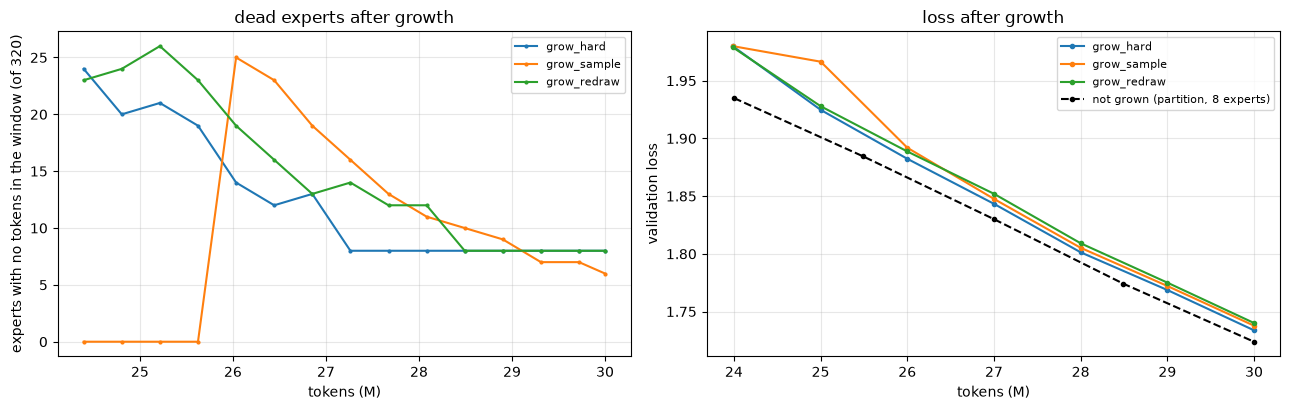

In [8]:
src = best_at_grow(); BASE = RUNS[src]
G = {n: R(n) for n in GROW_RUNS}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
NUM["grow"] = dict(from_method=src)
for name, log in G.items():
    tr = log["train"]
    t = [r["tokens"]/1e6 for r in tr]; dead = [sum(r["routing"]["dead"]) for r in tr]
    ax[0].plot(t, dead, "-o", ms=2, label=name)
    e = log["evals"]; ax[1].plot([x["tokens"]/1e6 for x in e], [x["val_loss"] for x in e], "-o", ms=3, label=name)
    fam = np.array(tr[-1]["routing"]["dead_by_family"])           # (layers, 8 families): dead clones per family
    NUM["grow"][name] = dict(dead_max=max(dead), dead_last=dead[-1], final_val=log["final_val_loss"],
                             families_all_alive=int((fam == 0).sum()), families_one_left=int((fam == 3).sum()),
                             dead_curve=list(zip(t, dead)))
    print(f"{name:12s} dead experts (of 320): worst {max(dead)}, last window {dead[-1]};  families (of 80) with all 4 "
          f"clones alive {int((fam == 0).sum())}, with only 1 alive {int((fam == 3).sum())};  final val {log['final_val_loss']:.4f}")
eb = [x for x in BASE["evals"] if x["tokens"] >= GROW_AT - 1]
ax[1].plot([x["tokens"]/1e6 for x in eb], [x["val_loss"] for x in eb], "k--o", ms=3, label=f"not grown ({src}, 8 experts)")
NUM["grow"]["baseline_final_val"] = BASE["final_val_loss"]
print(f"{'not grown':12s} final val {BASE['final_val_loss']:.4f}")
ax[0].set(xlabel="tokens (M)", ylabel="experts with no tokens in the window (of 320)", title="dead experts after growth")
ax[1].set(xlabel="tokens (M)", ylabel="validation loss", title="loss after growth")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(ART / "clone_growth.png", dpi=130); plt.show()

## 7. What did the experts learn?

The course's claim (Section 9) is that experts specialise by kind of token (punctuation, function words, names,
numbers), not by subject. TinyStories is one genre with no subjects, so only the token-type half can be tested here.

Every validation token is put in one of six types: punctuation, newline/end of text, number, capitalised word,
function word, other word. Three measures:
- **Token type.** How many bits a token's top-1 expert tells you about its type. Chance is measured by shuffling the
  types; the ceiling is the type's own entropy.
- **Neighbours.** How often the next token picks the same top-1 expert. The course quotes Mixtral at 24–28% against
  12.5% chance.
- **Expert similarity.** The mean cosine similarity between experts' weights. Copied experts start at exactly 1.

In [9]:
cats, tok = A.token_categories()
NUM["specialisation"] = {}
spec_models = {f"upcycled ({best})": (moe_config(best), RES / f"moe_{best}.pt"), "from scratch": (moe_config("copy"), RES / "moe_scratch.pt")}
SPEC = {}
for name, (cfg, path) in spec_models.items():
    m = GPT(cfg); m.load_state_dict(torch.load(path, map_location="cpu")); m = m.to(DEV)
    toks, ch = A.route_validation(m, DEV)
    rows = A.specialisation(toks, ch, cats)
    sim = A.expert_similarity(m)
    SPEC[name] = (toks, ch)
    NUM["specialisation"][name] = dict(rows=rows, expert_cosine=sim)
    print(f"--- {name}")
    print(f"{'layer':>5s} {'type info (bits)':>16s} {'shuffled':>9s} {'max':>5s} {'same expert next':>17s} {'chance':>7s} {'expert cosine':>14s}")
    for r, c in zip(rows, sim):
        print(f"{r['layer']:5d} {r['mi_type']:16.3f} {r['mi_shuffled']:9.3f} {r['h_type']:5.2f} {r['same_next']:17.1%} {r['same_next_chance']:7.1%} {c:14.3f}")
    del m

--- upcycled (partition)
layer type info (bits)  shuffled   max  same expert next  chance  expert cosine
    0            0.094     0.001  1.84             48.6%   12.6%          0.037
    1            0.076     0.001  1.84             33.2%   13.5%          0.104
    2            0.074     0.001  1.84             41.8%   16.0%          0.112
    3            0.110     0.000  1.84             43.4%   15.8%          0.096
    4            0.061     0.000  1.84             45.6%   13.7%          0.080
    5            0.041     0.001  1.84             44.8%   14.0%          0.067
    6            0.042     0.001  1.84             44.3%   13.2%          0.057
    7            0.038     0.000  1.84             43.9%   13.6%          0.056
    8            0.080     0.001  1.84             44.4%   13.3%          0.055
    9            0.058     0.001  1.84             40.1%   12.6%          0.054


--- from scratch
layer type info (bits)  shuffled   max  same expert next  chance  expert cosine
    0            0.547     0.000  1.84             11.3%   12.9%          0.011
    1            0.629     0.001  1.84             17.9%   13.1%          0.035
    2            0.518     0.001  1.84             21.1%   13.0%          0.047
    3            0.441     0.000  1.84             17.3%   14.1%          0.049
    4            0.534     0.001  1.84             18.1%   13.2%          0.033
    5            0.462     0.001  1.84             16.4%   13.6%          0.032
    6            0.416     0.001  1.84             22.6%   13.3%          0.033
    7            0.207     0.000  1.84             35.9%   15.4%          0.036
    8            0.457     0.001  1.84             31.3%   14.5%          0.024
    9            0.340     0.001  1.84             23.8%   15.4%          0.033


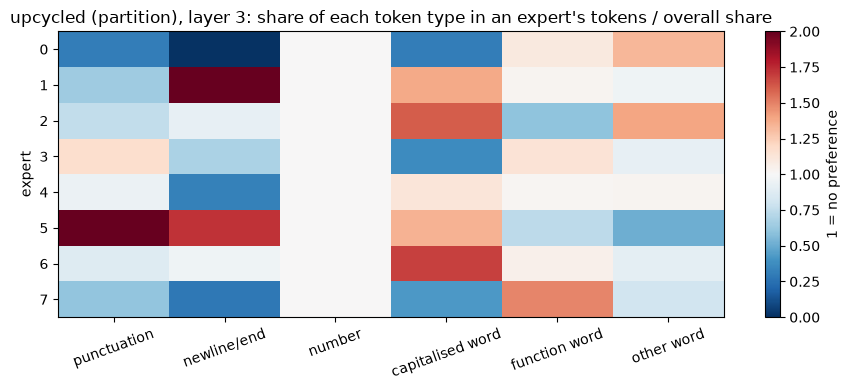

layer 3: each expert's most over-represented tokens (lift over overall frequency)
  expert 0: ' home' x5.2, ' back' x5.2, ' away' x5.2, ' take' x5.2, ' took' x5.0, ' help' x4.9, ' got' x4.7, ' found' x4.4
  expert 1: 'Once' x4.5, 'The' x4.4, ' wanted' x4.4, ' boy' x4.3, ' liked' x4.2, ' can' x4.1, ' time' x3.9, ' things' x3.7
  expert 2: ' day' x7.7, ' park' x6.3, ' then' x6.1, ' It' x4.6, ' Max' x4.3, ' "' x3.9, '!' x2.7, ' little' x2.7
  expert 3: ' around' x8.8, ' there' x5.7, ' at' x5.2, ' looked' x4.5, 'I' x4.3, ' up' x4.1, ' too' x4.0, ' in' x3.4
  expert 4: ' Sara' x4.0, "'m" x3.3, ' cat' x3.2, ' house' x3.1, ' big' x2.9, ' their' x2.7, ' small' x2.7, ' too' x2.7
  expert 5: ' upon' x6.3, '."' x5.8, 'One' x5.4, '!"' x5.1, ' One' x4.7, '?"' x4.7, ' saw' x3.2, ' But' x3.2
  expert 6: ' said' x19.2, ' named' x13.4, ' happy' x9.5, ' Tim' x6.2, ' "' x3.3, ' and' x2.5, ',' x1.9, '\n' x1.2
  expert 7: ' became' x12.5, ' told' x11.5, ' did' x7.1, ' that' x5.9, ' went' x5.8, ' they' x5.6

In [10]:
name = f"upcycled ({best})"; toks, ch = SPEC[name]
layer = int(np.argmax([r["mi_type"] for r in NUM["specialisation"][name]["rows"]]))
mix = A.type_mix(toks, ch, cats, layer)
overall = np.bincount(cats[toks], minlength=len(A.CATEGORIES)) / len(toks)
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(np.divide(mix, overall, out=np.ones_like(mix), where=overall > 0), cmap="RdBu_r", vmin=0, vmax=2, aspect="auto")
ax.set(xticks=range(len(A.CATEGORIES)), xticklabels=A.CATEGORIES, ylabel="expert",
       title=f"{name}, layer {layer}: share of each token type in an expert's tokens / overall share")
plt.setp(ax.get_xticklabels(), rotation=20); fig.colorbar(im, label="1 = no preference")
fig.tight_layout(); fig.savefig(ART / "expert_token_types.png", dpi=130); plt.show()
print(f"layer {layer}: each expert's most over-represented tokens (lift over overall frequency)")
for e, tt in A.top_tokens(toks, ch, tok, layer).items():
    print(f"  expert {e}: " + ", ".join(f"{t!r} x{l}" for t, l in tt))
NUM["specialisation_layer"] = layer

## 8. Summary

In [11]:
print(f"{'run':24s} {'tokens':>8s} {'total':>7s} {'active':>7s} {'final val':>10s} {'tok/s':>7s} {'peak GiB':>9s}")
rows = [("dense", D)] + [(f"MoE by {m}", RUNS[m]) for m in METHODS] + [("MoE from scratch", SC)] + [(n, G[n]) for n in GROW_RUNS]
for name, log in rows:
    print(f"{name:24s} {log['tokens_end']/1e6:7.1f}M {log['n_params']/1e6:6.1f}M {log['n_active']/1e6:6.1f}M "
          f"{log['final_val_loss']:10.4f} {log['tok_per_s']:7.0f} {log['peak_bytes']/GiB:9.2f}")
NUM["summary"] = {name: dict(tokens=log["tokens_end"], total=log["n_params"], active=log["n_active"], final_val=log["final_val_loss"],
                             final_train=log["final_train_loss"], tok_s=log["tok_per_s"], peak_gib=log["peak_bytes"]/GiB,
                             minutes=log["train_seconds"]/60) for name, log in rows}
(ART / "s14_numbers.json").write_text(json.dumps(NUM, indent=1, default=float))
print("saved", ART / "s14_numbers.json")

run                        tokens   total  active  final val   tok/s  peak GiB
dense                       30.0M   21.0M   21.0M     1.7045   16021      6.47
MoE by copy                 30.0M  103.6M   32.8M     1.7178    6697     11.03
MoE by drop                 30.0M  103.6M   32.8M     1.7105    6867     11.07
MoE by partition            30.0M   68.2M   32.8M     1.6973    7211     10.57
MoE from scratch            30.0M  103.6M   32.8M     1.6779    7119     11.02
grow_hard                   30.0M  209.8M   32.9M     1.7080    4630     12.20
grow_sample                 30.0M  209.8M   32.9M     1.7133    4643     12.20
grow_redraw                 30.0M  209.8M   32.9M     1.7141    4711     12.21
saved /Users/pradeep/AL/ERAv5/s14/submission_artifacts/s14_numbers.json
